In [ ]:
import os
import gc
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Export_GAF_Individuel/GAF_1024"
CLASSES = ["Normal", "IRF", "ORF"]

IMG_SIZE = (256, 256)
BATCH_SIZE = 8
EPOCHS = 25

In [ ]:
def load_data(base_path, classes):
    data = {cls: [] for cls in classes}
   # j'ai  crée un dictionnaire : {"Normal": [], "IRF": [], "ORF": []}
    for cls in classes:
        path = os.path.join(base_path, cls, "GADF")
        if not os.path.exists(path):
            path = os.path.join(base_path, cls)
 # ici pour chercher le dossier GADF, sinon prend le dossier de la classe directement

        files = [os.path.join(path, f) for f in os.listdir(path)
                 if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:400]

        for f in files:
            img = load_img(f, target_size=IMG_SIZE, color_mode="grayscale")
            img = img_to_array(img).astype("float32") / 255.0
            img = (img - np.mean(img)) / (np.std(img) + 1e-7)
            data[cls].append(img)

        print(cls, len(data[cls]))

    return data

In [ ]:
def split_data(data):
    train, val, test = {}, {}, {}

    for c in CLASSES:
        imgs = data[c]
        np.random.shuffle(imgs)
        # → mélange aléatoirement les images


        n1 = int(0.15 * len(imgs))    # → 15% pour train
        n2 = int(0.30 * len(imgs))

        train[c] = imgs[:n1]
        val[c] = imgs[n1:n2]
        test[c] = imgs[n2:]

        print(c, len(train[c]), len(val[c]), len(test[c]))

    return train, val, test

In [ ]:
class SiameseGenerator(tf.keras.utils.Sequence):
    def __init__(self, data, batch_size=8, steps=1000, **kwargs):
        super().__init__(**kwargs)

        self.data = data
        self.batch_size = batch_size
        self.steps = steps    #  nombre total de batches par epoch
        self.classes = list(data.keys())

    def __len__(self):
        return self.steps

    def __getitem__(self, idx):
        A, B, Y = [], [], []

        for _ in range(self.batch_size):

            c1 = np.random.choice(self.classes)
            c2 = np.random.choice(self.classes)


            img1 = self.data[c1][np.random.randint(len(self.data[c1]))]
            img2 = self.data[c2][np.random.randint(len(self.data[c2]))]

            if c1 == c2:
                label = 0
            else:
                label = 1

            A.append(img1)
            B.append(img2)
            Y.append(label)

        return (np.array(A), np.array(B)), np.array(Y)

In [ ]:
def build_encoder(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),   # ici entrée : image 256×256×1

        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        layers.Dense(128),
        layers.Lambda(lambda x: tf.math.l2_normalize(x, axis=1))
    ])

    #ici l'encoder transforme une image 256×256 en un vecteur de 128 dimensions (embedding). C'est la "signature" de l'image.


In [ ]:
def build_model(input_shape):
    encoder = build_encoder(input_shape)

    A = layers.Input(shape=input_shape)
    B = layers.Input(shape=input_shape)

    emb_A = encoder(A)
    emb_B = encoder(B)

    L1 = layers.Lambda(lambda x: tf.abs(x[0] - x[1]))([emb_A, emb_B])

    x = layers.Dense(64, activation='relu')(L1)
    out = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model([A, B], out)

    return model, encoder

In [ ]:
all_data = load_data(BASE_PATH, CLASSES)
train_data, val_data, test_data = split_data(all_data)

model, encoder = build_model((256,256,1))

model.compile(
    optimizer=optimizers.Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

train_gen = SiameseGenerator(train_data, BATCH_SIZE, 2000)
val_gen = SiameseGenerator(val_data, BATCH_SIZE, 500)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS
)

Normal 100
IRF 100
ORF 100
Normal 15 15 70
IRF 15 15 70
ORF 15 15 70
Epoch 1/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 90s 40ms/step - accuracy: 0.8760 - loss: 0.2845 - val_accuracy: 0.8420 - val_loss: 0.3525
Epoch 2/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 79s 39ms/step - accuracy: 0.9770 - loss: 0.0853 - val_accuracy: 0.8155 - val_loss: 0.4026
Epoch 3/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 78s 39ms/step - accuracy: 0.9812 - loss: 0.0609 - val_accuracy: 0.8800 - val_loss: 0.2950
Epoch 4/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 79s 39ms/step - accuracy: 0.9879 - loss: 0.0422 - val_accuracy: 0.8210 - val_loss: 0.5017
Epoch 5/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 79s 39ms/step - accuracy: 0.9891 - loss: 0.0387 - val_accuracy: 0.8460 - val_loss: 0.4561
Epoch 6/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 79s 39ms/step - accuracy: 0.9932 - loss: 0.0254 - val_accuracy: 0.8680 - val_loss: 0.3991
Epoch 7/25
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 79s 40ms/step - accuracy: 0.9908 - loss: 0.0298 - val_accuracy: 0.8525 - val_loss: 0.4272
Epoch 8

In [ ]:
support_set = {
    "Normal": train_data["Normal"][:5],
    "IRF": train_data["IRF"][:5],
    "ORF": train_data["ORF"][:5]
}
#  j'ai pris 5 images de référence par classe

In [ ]:
def predict(encoder, img, support_set):

    emb = encoder.predict(img[np.newaxis], verbose=0)
   # calcule l'embedding de l'image à classifier
    scores = {}

    for cls in support_set:
        dists = []

        for ref in support_set[cls]:
            ref_emb = encoder.predict(ref[np.newaxis], verbose=0)
            dists.append(np.linalg.norm(emb - ref_emb))
              #  distance euclidienne entre l'embedding et chaque référence

        scores[cls] = np.mean(dists)
        #  distance moyenne à la classe

    return min(scores, key=scores.get)
        #  retourne la classe la plus proche (distance minimale)


       # ici C'est le cœur du few-shot : on classifie en trouvant quelle classe du support set est la plus proche dans l'espace des embeddings.

In [ ]:
correct = 0
total = 0

for cls in test_data:
    for img in test_data[cls][:50]:

        pred = predict(encoder, img, support_set)

        if pred == cls:
            correct += 1
        total += 1

print(" Few-Shot Accuracy:", correct / total)

🔥 Few-Shot Accuracy: 0.86


In [ ]:
y_true = []
y_pred = []
y_scores = []

for cls in test_data:
    for img in test_data[cls]:

        emb = encoder.predict(img[np.newaxis], verbose=0)

        dists_per_class = []

        for c in CLASSES:
            dists = []
            for ref in support_set[c]:
                ref_emb = encoder.predict(ref[np.newaxis], verbose=0)
                dists.append(np.linalg.norm(emb - ref_emb))

            dists_per_class.append(np.mean(dists))

        # prédiction = distance minimale
        pred_class = CLASSES[np.argmin(dists_per_class)]

        y_true.append(cls)
        y_pred.append(pred_class)


        y_scores.append([-d for d in dists_per_class])

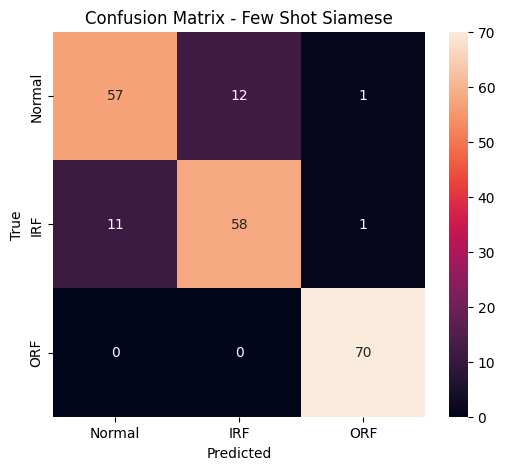

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=CLASSES)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=CLASSES,
            yticklabels=CLASSES)

plt.title("Confusion Matrix - Few Shot Siamese")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

              precision    recall  f1-score   support

         IRF       0.83      0.83      0.83        70
      Normal       0.84      0.81      0.83        70
         ORF       0.97      1.00      0.99        70

    accuracy                           0.88       210
   macro avg       0.88      0.88      0.88       210
weighted avg       0.88      0.88      0.88       210



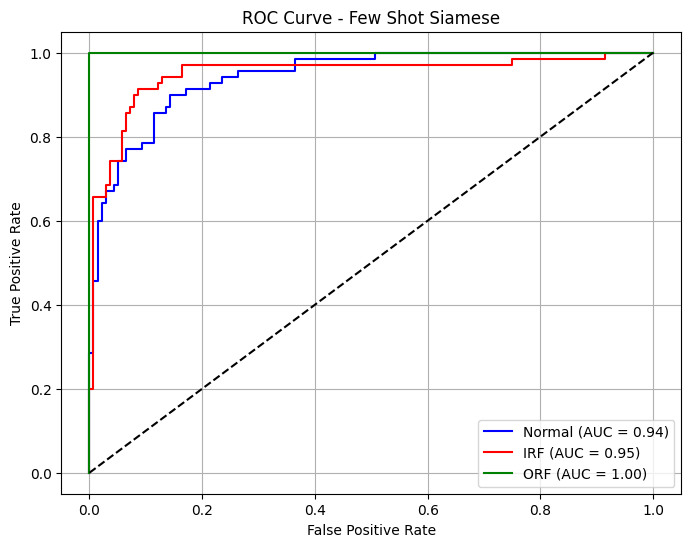

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred))
from sklearn.preprocessing import label_binarize
import numpy as np

y_true_bin = label_binarize(y_true, classes=CLASSES)
y_scores = np.array(y_scores)
from sklearn.metrics import roc_curve, auc

fpr = {}
tpr = {}
roc_auc = {}

for i in range(len(CLASSES)):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
plt.figure(figsize=(8,6))

colors = ['blue', 'red', 'green']

for i, color in zip(range(len(CLASSES)), colors):
    plt.plot(fpr[i], tpr[i], color=color,
             label=f'{CLASSES[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Few Shot Siamese")
plt.legend()
plt.grid()
plt.show()

In [ ]:
print(" Mean AUC:", np.mean(list(roc_auc.values())))

 Mean AUC: 0.964795918367347


In [ ]:

def predict_fewshot(encoder, img, support_set):
    emb = encoder.predict(img[np.newaxis], verbose=0)

    scores = {}

    for cls in support_set:
        dists = []
        for ref in support_set[cls]:
            ref_emb = encoder.predict(ref[np.newaxis], verbose=0)
            dist = np.linalg.norm(emb - ref_emb)
            dists.append(dist)

        scores[cls] = np.mean(dists)

    return min(scores, key=scores.get)

support_set1 = {
    "Normal": test_data["Normal"][:5],
    "IRF": test_data["IRF"][:5],
    "ORF": test_data["ORF"][:5]
}


correct = 0
total = 0

for cls in CLASSES:

    for img in test_data[cls][5:]:

        pred = predict_fewshot(encoder, img, support_set1)

        if pred == cls:
            correct += 1

        total += 1

print(" Few-Shot Accuracy (test support):", correct / total)

🔥 Few-Shot Accuracy (test support): 0.8205128205128205


🔄 Extraction des embeddings...
🧪 Calcul t-SNE...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


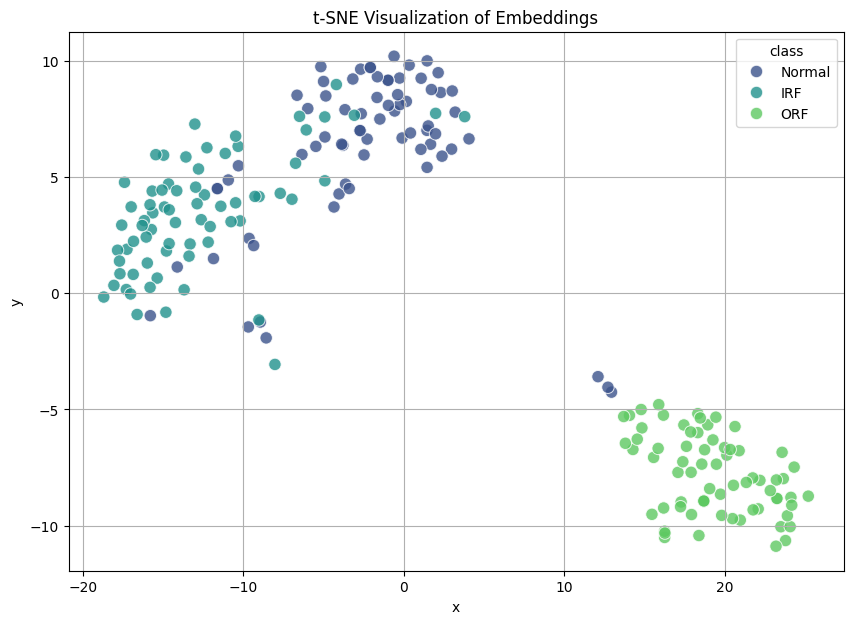

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
X = []
y = []

print("🔄 Extraction des embeddings...")

for cls in CLASSES:
    # prendre max 100 images pour éviter lenteur
    imgs = np.array(test_data[cls][:100])

    emb = encoder.predict(imgs, verbose=0)

    X.append(emb)
    y += [cls] * len(emb)

X = np.vstack(X)

print("🧪 Calcul t-SNE...")

tsne = TSNE(
    n_components=2,
    perplexity=30,
    n_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X)

df = pd.DataFrame()
df["x"] = X_tsne[:, 0]
df["y"] = X_tsne[:, 1]
df["class"] = y

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="x",
    y="y",
    hue="class",
    palette="viridis",
    s=80,
    alpha=0.8
)

plt.title("t-SNE Visualization of Embeddings")
plt.grid(True)
plt.show()